In [1]:
import os
import numpy as np
os.environ["KERAS_BACKEND"] = "jax"
import keras
from keras import layers
from datasets import load_dataset


In [2]:
dataset = load_dataset("zalando-datasets/fashion_mnist")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


Formattazione dei samples

In [3]:
# Creo un tensore train_image con le immagini del dataset
# ne modifico la forma, avendo 60000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

x = np.array(dataset["train"]["image"])

train_images = x.reshape((60000, 28 * 28))
train_images= train_images.astype("float32")
train_images /= 255.0

train_labels = np.array(dataset["train"]["label"])

print("------TRAINING SAMPLES-------")
print(train_images.shape)
print(train_images.dtype)
print(train_images.min())
print(train_images.max())

print("------TRAINING LABELS-------")
print(train_labels.shape)
print(train_labels.dtype)
print(train_labels.min())
print(train_labels.max())


# Creo un tensore tratest_images con le immagini del dataset
# ne modifico la forma, avendo 10000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

y = np.array(dataset["test"]["image"])

test_images = y.reshape((10000, 28 * 28))
test_images= test_images.astype("float32")
test_images /= 255.0

test_labels = np.array(dataset["test"]["label"])

print("------TEST SAMPLES-------")
print(test_images.shape)
print(test_images.dtype)
print(test_images.min())
print(test_images.max())

print("------TEST LABELS-------")
print(test_labels.shape)
print(test_labels.dtype)
print(test_labels.min())
print(test_labels.max())


------TRAINING SAMPLES-------
(60000, 784)
float32
0.0
1.0
------TRAINING LABELS-------
(60000,)
int64
0
9
------TEST SAMPLES-------
(10000, 784)
float32
0.0
1.0
------TEST LABELS-------
(10000,)
int64
0
9


In [4]:
keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(28*28,), name = "Input_layer")
features_1 = layers.Dense(128, activation="relu", name="Uno")(inputs)
filtered_features = layers.Dropout(0.2)(features_1)
features_2 = layers.Dense(64, activation="relu")(filtered_features)
output = layers.Dense(10, activation="softmax")(features_2)


model = keras.Model(
    inputs = inputs,
    outputs = output,
    name = "Fashion_MNIST_model_mini_dropout"
)

print("-----------MODEL SUMMARY-----------")
model.summary()

print("-----------MODEL LAYERS-------------")
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=5,
    restore_best_weights=True
)




-----------MODEL SUMMARY-----------


Model: "Fashion_MNIST_model_mini_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Uno (Dense)                     │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

-----------MODEL LAYERS-------------
0 Input_layer InputLayer
1 Uno Dense
2 dropout Dropout
3 dense Dense
4 dense_1 Dense


Epoch 1/20


/opt/miniconda3/envs/ai_env/lib/python3.12/site-packages/jax/_src/core.py:1976: UserWarning: Explicitly requested dtype int64 requested in ShapeDtypeStruct is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return aval_fn(x)


384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 643us/step - accuracy: 0.7811 - loss: 0.6273 - val_accuracy: 0.8411 - val_loss: 0.4468
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step - accuracy: 0.8475 - loss: 0.4272 - val_accuracy: 0.8583 - val_loss: 0.3977
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - accuracy: 0.8576 - loss: 0.3886 - val_accuracy: 0.8651 - val_loss: 0.3731
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 404us/step - accuracy: 0.8689 - loss: 0.3613 - val_accuracy: 0.8708 - val_loss: 0.3516
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step - accuracy: 0.8733 - loss: 0.3453 - val_accuracy: 0.8700 - val_loss: 0.3498
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step - accuracy: 0.8786 - loss: 0.3300 - val_accuracy: 0.8832 - val_loss: 0.3281
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step - accuracy: 0.8828 - loss: 0.3176 - val_accuracy: 0.8827 - val_loss: 0.3282
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 409us/step - accuracy: 0.8838 - loss: 0.3103 - val_accurac

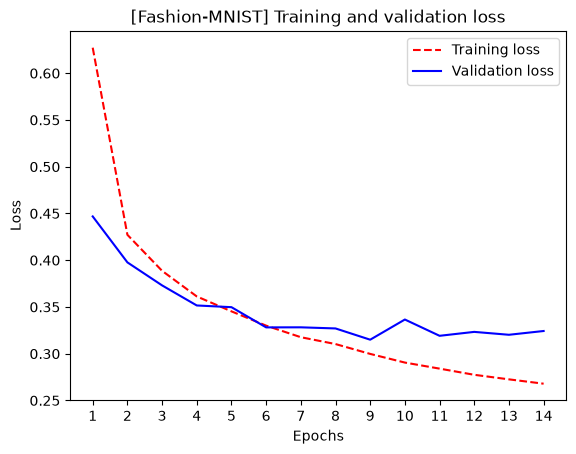

In [5]:

history = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=125,
    validation_split=0.2,
    callbacks = [early_stopping]
    )


import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("[Fashion-MNIST] Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

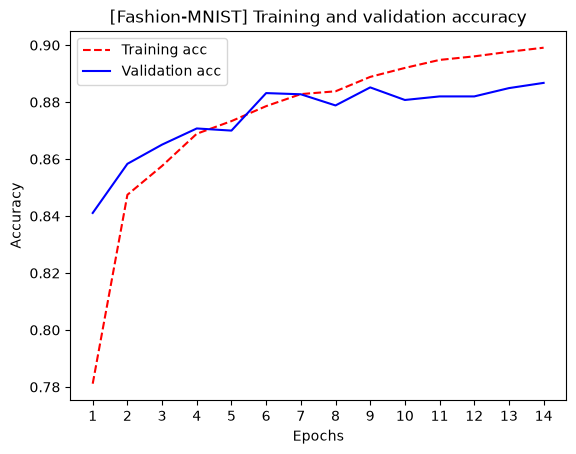

In [6]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[Fashion-MNIST] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [7]:
print(f"Ultima training accuracy: "
      f"{history.history['accuracy'][-1]:.2%}")

print(f"Ultima validation accuracy: "
      f"{history.history['val_accuracy'][-1]:.2%}")

print(f"Migliore validation accuracy: "
      f"{max(history.history['val_accuracy']):.2%}")

Ultima training accuracy: 89.91%
Ultima validation accuracy: 88.67%
Migliore validation accuracy: 88.67%


In [8]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print(f"Epoca migliore: {best_epoch + 1}")
print(
    "Validation loss minima:",
    history.history["val_loss"][best_epoch]
)
print(
    "Validation accuracy in quell'epoca:",
    f"{history.history['val_accuracy'][best_epoch]:.2%}"
)

Epoca migliore: 9
Validation loss minima: 0.31498199701309204
Validation accuracy in quell'epoca: 88.52%


| Modello        | Parametri | Epoca | Validation loss ↓ | Validation accuracy ↑ |
|----------------|-----------|-------|-------------------|-----------------------|
| Baseline       | 813.002    | 10    | 0.3195            | **89.10%**            |
| Mini           | 109.386    | 8     | 0.3382            | 87.59%                |
| Mini + Dropout | 109.386    | 9     | **0.3150**        | 88.52%                |


il Dropout ottiene una loss leggermente migliore della baseline, ma un’accuracy inferiore. È possibile perché:
    - Accuracy: conta quante classi previste sono corrette.
    - Crossentropy: considera anche la probabilità assegnata alla classe vera.
Per esempio, assegnare alla classe vera probabilità 0.60 oppure 0.95 può dare la stessa classificazione corretta, ma produce loss diverse.


Conclusioni:
    Rispetto al modello di Baseline, il modello mini + dropout permette di ridurre di circa l'86% il numero di parametri ottenendo una loss minore della baseline


In [14]:
val_images = train_images[48000:]
val_labels = train_labels[48000:]

probabilities = model.predict(val_images, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

print("Probability shape:")
print(probabilities.shape)
print("Predicted labels shape:")
print(predicted_labels.shape)

correct = predicted_labels == val_labels
print(f"Numero di elementi correttamente etichettati: {correct.sum()}")
print(f"Numero di elementi non predetti correttamente: {len(val_labels)-correct.sum()}")
print(f"Frazione corretta: {correct.mean():.2%}")


#for i, label in enumerate(predicted_labels):
#    print(f"Predicted label: {label}", end='\t')
#    print(f"Original label: {val_labels[i]}")
#

Probability shape:
(12000, 10)
Predicted labels shape:
(12000,)
Numero di elementi correttamente etichettati: 10622
Numero di elementi non predetti correttamente: 1378
Frazione corretta: 88.52%
